<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 5, Odometría visual y SLAM RGB-D**

Un robot que entra a una sala tiene que responder dos preguntas a la vez, mientras se mueve:

* localización: ¿dónde estoy?
* mapeo: ¿cómo es lo que me rodea?



---
bajamos el dataset Lounge (Choi y Koltun): 3 000 frames RGB-D de 640 × 480 y la trayectoria de referencia. Son 1.9 GB

In [ ]:
!wget -q https://github.com/isl-org/open3d_downloads/releases/download/20220301-data/LoungeRGBDImages.zip
!unzip -q -o LoungeRGBDImages.zip -d lounge && rm LoungeRGBDImages.zip

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.optimize import least_squares
from scipy.spatial.transform import Rotation

##**1.- Los datos**

la cámara es una PrimeSense (como la Kinect). Su K es la de siempre, y la profundidad viene en milímetros

In [ ]:
# matriz de calibración de la cámara
# esta matriz describe el lente y el sensor de la cámara (distancia focal y centro de la imagen)
# y sirve para traducir entre píxeles de la imagen y direcciones en el mundo 3D
K = np.array([[525.0, 0, 319.5],
              [0, 525.0, 239.5],
              [0, 0, 1]])
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]

# con la foto de color encuentra los puntos (ORB) y con la profundidad los pasa a 3D para calcular el movimiento (PnP)
def leer(f):
    # leemos la imagen de color y la de profundidad del frame f (empiezan en 1)
    rgb = cv2.imread(f"lounge/color/{f:06d}.png")
    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
    z = cv2.imread(f"lounge/depth/{f:06d}.png", cv2.IMREAD_UNCHANGED)
    z = z / 1000.0  # paso de milímetros a metros (0 = sin dato)
    return rgb, z


# El archivo guarda dónde estaba la cámara en cada uno de los 3000 frames, y este código lo leemos y lo guardamos en GT
# Cada frame ocupa 5 líneas en el archivo:
# la primera es un número de frame, que no usamos
# las otras 4 forman una tabla de 4×4 que dice dónde estaba la cámara y hacia dónde miraba

lineas = open("lounge/lounge_trajectory.log").read().split("\n")
GT = []
for k in range(0, len(lineas) - 4, 5):
    T = np.loadtxt(lineas[k + 1:k + 5])  # las 4 filas de la matriz
    GT.append(T)

# GT[0] es la pose del frame 1, GT[1] la del frame 2, y así hasta el 3000
GT = np.array(GT)  # GT[f - 1] es la pose del frame f

print(len(GT), "poses")

3000 poses


algunos frames con su profundidad

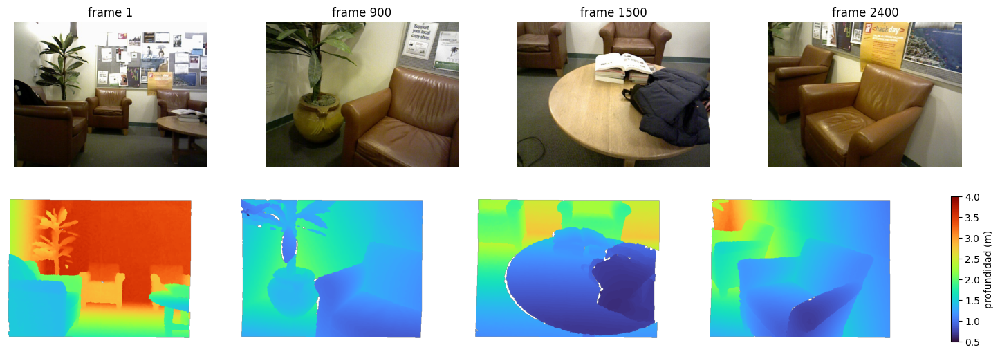

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(18, 6))
for k, f in enumerate([1, 900, 1500, 2400]):
    rgb, z = leer(f)
    ax[0, k].imshow(rgb)
    ax[0, k].set_title(f"frame {f}")
    # los píxeles sin dato (z = 0) los dejo en blanco
    im = ax[1, k].imshow(np.where(z > 0, z, np.nan), cmap="turbo", vmin=0.5, vmax=4)
for a in ax.ravel():
    a.axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.02, label="profundidad (m)")
plt.show()

la trayectoria de referencia vista desde arriba. En este dataset el eje y apunta hacia el piso

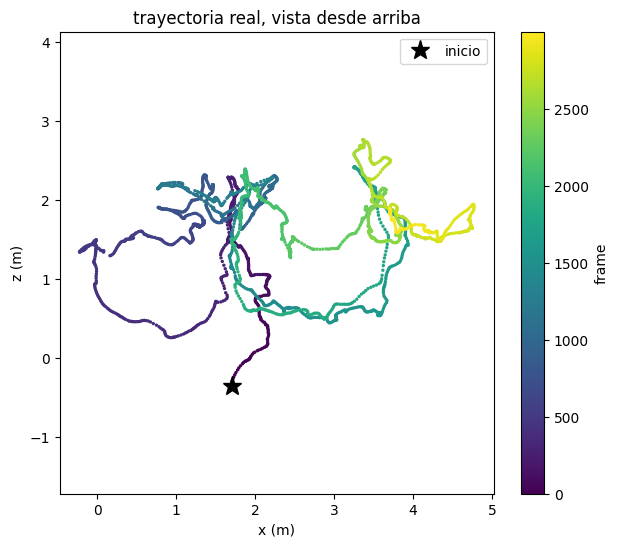

In [ ]:
# la posición de la cámara es la última columna de cada matriz
C = GT[:, :3, 3]
plt.figure(figsize=(7, 6))
plt.scatter(C[:, 0], C[:, 2], c=np.arange(len(C)), cmap="viridis", s=2)
plt.colorbar(label="frame")
plt.plot(C[0, 0], C[0, 2], "k*", ms=14, label="inicio")
plt.axis("equal"); plt.xlabel("x (m)"); plt.ylabel("z (m)")
plt.legend(); plt.title("trayectoria real, vista desde arriba")
plt.show()

##**2.- Odometría visual**

usamos un frame de cada 3 (10 por segundo). Para cada par de frames seguidos:

1. features **ORB** (rápidos, descriptores binarios) y matching con el test de Lowe
2. los puntos del frame anterior ya tienen profundidad -> son **puntos 3D**
3. con parejas 3D–2D la pose sale con **PnP + RANSAC** (clase 4). No hace falta la matriz esencial, y la escala sale en metros

In [ ]:
FRAMES = list(range(1, len(GT) + 1, 3))  # uso un frame de cada 3
orb = cv2.ORB_create(2000)
bf = cv2.BFMatcher(cv2.NORM_HAMMING)

def features(rgb):
    # detectamos puntos ORB y nos quedamos con sus coordenadas y descriptores
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    kp, des = orb.detectAndCompute(gris, None)
    pts = np.float32([k.pt for k in kp])
    return pts, des

def parejas(d1, d2):
    # buscamos los 2 vecinos más parecidos y aplicamos el test de Lowe
    pares = []
    for m in bf.knnMatch(d1, d2, k=2):
        if len(m) == 2 and m[0].distance < 0.8 * m[1].distance:
            pares.append((m[0].queryIdx, m[0].trainIdx))
    return np.array(pares).reshape(-1, 2)

def a_3d(u, v, z):
    # paso de píxel (u, v) + profundidad z a un punto 3D en la cámara (clase 2)
    X = (u - cx) * z / fx
    Y = (v - cy) * z / fy
    return np.column_stack([X, Y, z])

def pose_relativa(p1, z1, p2, pares, minimo=15):
    # calculamos dónde está la cámara 2 vista desde la cámara 1
    # devolvemos la matriz 4x4 y cuántos inliers dio RANSAC
    if len(pares) < minimo:
        return None, 0

    # tomamos los puntos del frame 1 y leemos su profundidad
    u1 = p1[pares[:, 0], 0]
    v1 = p1[pares[:, 0], 1]
    z = z1[v1.astype(int), u1.astype(int)]

    # me quedamos con los que tienen profundidad confiable (entre 0.3 y 5 m)
    ok = (z > 0.3) & (z < 5)
    if ok.sum() < minimo:
        return None, 0
    X = a_3d(u1[ok], v1[ok], z[ok])      # puntos 3D en la cámara 1
    x2 = p2[pares[ok, 1]]                # dónde se ven en la imagen 2

    # PnP con RANSAC: buscamos cuánto se movió la cámara entre la foto 1 y la foto 2, descartando las parejas malas
    exito, rvec, t, inl = cv2.solvePnPRansac(X, x2, K, None, reprojectionError=2.0,
                                             iterationsCount=200, flags=cv2.SOLVEPNP_EPNP)
    if not exito or inl is None or len(inl) < minimo:
        return None, 0

    # refinamos la pose usando solo los inliers
    inl = inl[:, 0]
    rvec, t = cv2.solvePnPRefineLM(X[inl], x2[inl], K, None, rvec, t)

    # armamos la matriz 4x4. PnP nos da cámara1 -> cámara2, así que la invertimos
    # armamos la matriz 4×4 del paso entre dos fotos:
    T = np.eye(4)
    T[:3, :3] = cv2.Rodrigues(rvec)[0]
    T[:3, 3] = t[:, 0]
    return np.linalg.inv(T), len(inl)

un par de frames seguidos: las parejas que encontramos

1615 features | 366 parejas con Lowe | 165 inliers de PnP
la cámara se movió 0.9 cm


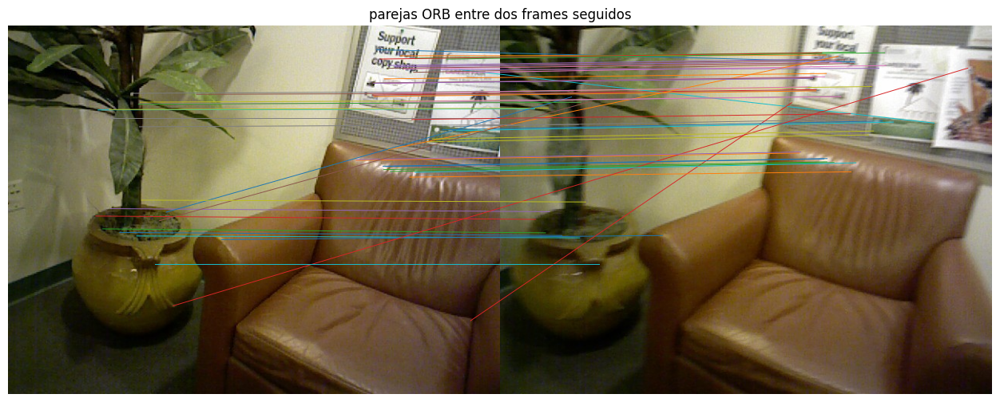

In [ ]:
# leemos dos fotos seguidas (las número 300 y 301 de la lista FRAMES) con su color y su profundidad
rgb1, z1 = leer(FRAMES[300])
rgb2, z2 = leer(FRAMES[301])

# buscamos puntos ORB en cada una: p son las posiciones de los puntos y d sus descriptores, que funcionan como la "huella" de cada punto
p1, d1 = features(rgb1)
p2, d2 = features(rgb2)

# emparejamos los puntos de las dos fotos
pares = parejas(d1, d2)

# calculamos el movimiento de la cámara con pose_relativa
T, n = pose_relativa(p1, z1, p2, pares)

print(len(p1), "features |", len(pares), "parejas con Lowe |", n, "inliers de PnP")
print(f"la cámara se movió {np.linalg.norm(T[:3, 3]) * 100:.1f} cm")

# pongo las dos imágenes lado a lado y dibujo una línea por pareja
plt.figure(figsize=(16, 6))
plt.imshow(np.hstack([rgb1, rgb2]))
for i, j in pares[::6]:  # dibujo una de cada 6 para que se vea algo
    plt.plot([p1[i, 0], p2[j, 0] + 640], [p1[i, 1], p2[j, 1]], lw=0.7)
plt.axis("off"); plt.title("parejas ORB entre dos frames seguidos")
plt.show()

* 1615 features: cuántos puntos encontró ORB en la foto 1. Le pedimos hasta 2000 (cv2.ORB_create(2000)), pero en esa foto encontró 1615.
* 366 parejas con Lowe: de esos 1615, cuántos encontraron su pareja en la foto 2 y pasaron el test de Lowe. Ese test se queda con una pareja solo si el punto más parecido es claramente mejor que el segundo más parecido. Si los dos se parecen casi igual, es una pareja dudosa y se descarta.
* 165 inliers de PnP: de esas 366 parejas, cuántas aceptó RANSAC, o sea las que coinciden con un mismo movimiento de la cámara. Las otras se descartan por ser parejas equivocadas o porque no tenían profundidad confiable.
* 0.9 cm = np.linalg.norm(T[:3, 3]) * 100: el largo del desplazamiento de la cámara entre las dos fotos, en centímetros.

----
Realizamos odometría visual sobre toda la secuencia: recorre las fotos una por una, calcula cuánto se movió la cámara entre cada par seguido y vamos sumando esos pasos para saber dónde está en cada momento.

In [ ]:
CADA = 10           # un keyframe cada 10 frames

# VO guarda dónde estaba la cámara en cada foto (su posición y hacia dónde miraba)
# según la odometría, medido desde la primera foto.
VO = [np.eye(4)]    # la primera pose es la identidad
fallos = 0
guardados = {}      # features de los keyframes

rgb, z = leer(FRAMES[0])
p, d = features(rgb)
guardados[0] = (p, d, z)

for k in range(1, len(FRAMES)):
    rgb2, z2 = leer(FRAMES[k])
    p2, d2 = features(rgb2)
    T, n = pose_relativa(p, z, p2, parejas(d, d2))
    if T is None:       # si falla, supongo que la cámara no se movió
        T = np.eye(4)
        fallos += 1
    VO.append(VO[-1] @ T)  # compongo con la pose anterior

    p, d, z = p2, d2, z2   # el frame actual pasa a ser el anterior
    if k % CADA == 0:
        guardados[k] = (p, d, z)

VO = np.array(VO)
print(len(FRAMES), "frames procesados |", fallos, "fallos de PnP")

1000 frames procesados | 11 fallos de PnP


##**3.- La deriva**

la odometría empieza en la identidad, expresamos la referencia respecto a su primer frame para comparar en el mismo sistema

In [ ]:
# llevo la trayectoria real al sistema de la primera cámara
T0_inv = np.linalg.inv(GT[0])
REF = np.array([T0_inv @ GT[f - 1] for f in FRAMES])

def ate(P, Q):
    # error de trayectoria: RMSE (en metros) entre las posiciones
    dif = P[:, :3, 3] - Q[:, :3, 3]
    return np.sqrt(np.mean(np.sum(dif ** 2, axis=1)))

# cuántos metros llevo recorridos en cada frame
pasos = np.linalg.norm(np.diff(REF[:, :3, 3], axis=0), axis=1)
recorrido = np.concatenate([[0], np.cumsum(pasos)])
# cuánto me equivoco en cada frame
error = np.linalg.norm(VO[:, :3, 3] - REF[:, :3, 3], axis=1)

print(f"ATE de la odometría: {ate(VO, REF) * 100:.1f} cm")
print(f"error al final: {error[-1]:.2f} m después de recorrer {recorrido[-1]:.1f} m")

ATE de la odometría: 52.6 cm
error al final: 0.88 m después de recorrer 51.4 m


a la izquierda las dos trayectorias, a la derecha cómo crece el error con los metros recorridos

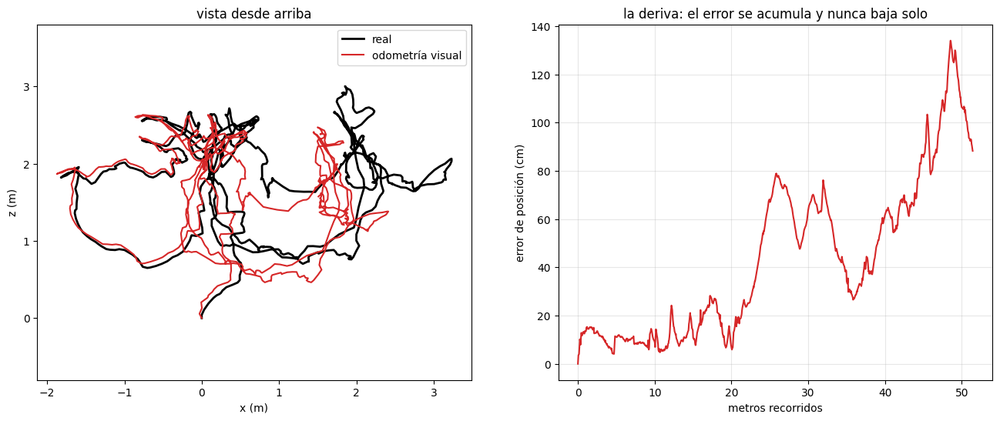

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].plot(REF[:, 0, 3], REF[:, 2, 3], "k", lw=2, label="real")
ax[0].plot(VO[:, 0, 3], VO[:, 2, 3], "tab:red", lw=1.5, label="odometría visual")
ax[0].axis("equal"); ax[0].legend(); ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("z (m)")
ax[0].set_title("vista desde arriba")

ax[1].plot(recorrido, error * 100, "tab:red")
ax[1].set_xlabel("metros recorridos"); ax[1].set_ylabel("error de posición (cm)")
ax[1].set_title("la deriva: el error se acumula y nunca baja solo"); ax[1].grid(alpha=0.3)
plt.show()

##**4.- Cierre de lazo y grafo de poses**

buscamos lazos: momentos en que la cámara volvió a un lugar por donde ya había pasado

In [ ]:
# KF son los índices 0, 10, 20, … (una foto de cada 10, unos 100 keyframes en total), se trabaja con pocas fotos para no tardar tanto
KF = list(range(0, len(FRAMES), CADA))  # índices de los keyframes
LAZOS = []

for a in range(len(KF)):
    for b in range(a + 20, len(KF)):  # pedimos al menos 20 keyframes (1 minuto) de diferencia
        i, j = KF[a], KF[b]
        # si según la odometría están lejos (mayor a 1 metro), ni lo intentamos
        if np.linalg.norm(VO[i, :3, 3] - VO[j, :3, 3]) > 1.0:
            continue

        # recuperamos los puntos ORB (p), sus descriptores (d) y la profundidad (z) de los dos keyframes,
        # que se guardaron durante la odometría, así no hay que volver a leer las fotos
        p1, d1, z1 = guardados[i]
        p2, d2, z2 = guardados[j]

        # emparejamos los puntos de las dos fotos y calcula el movimiento entre ellas, igual que en la odometría
        # minimo=30 pide más parejas que antes (en la odometría eran 15), porque acá un error sale caro
        T, n = pose_relativa(p1, z1, p2, parejas(d1, d2), minimo=30)
        if T is not None and n >= 60:  # muchos inliers: es el mismo lugar
            LAZOS.append((a, b, T, n))
            print(f"lazo: frame {FRAMES[i]} <-> frame {FRAMES[j]} ({n} inliers)")

print(len(KF), "keyframes |", len(LAZOS), "lazos")

lazo: frame 961 <-> frame 2191 (151 inliers)
lazo: frame 961 <-> frame 2221 (62 inliers)
lazo: frame 961 <-> frame 2251 (85 inliers)
lazo: frame 1261 <-> frame 1981 (96 inliers)
lazo: frame 1261 <-> frame 2011 (145 inliers)
100 keyframes | 5 lazos


un lazo: el mismo rincón visto con más de un minuto de diferencia

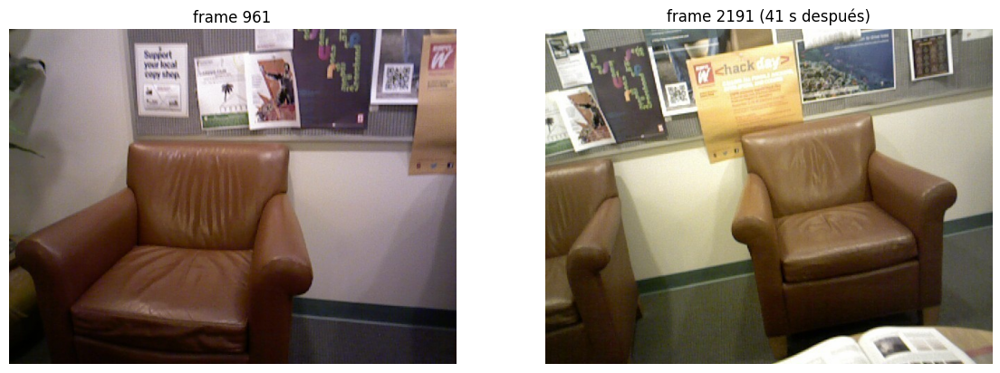

In [ ]:
if len(LAZOS) > 0:
    # elijo el lazo con más inliers
    mejor = LAZOS[0]
    for lazo in LAZOS:
        if lazo[3] > mejor[3]:
            mejor = lazo
    fa, fb = FRAMES[KF[mejor[0]]], FRAMES[KF[mejor[1]]]

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].imshow(leer(fa)[0]); ax[0].set_title(f"frame {fa}")
    ax[1].imshow(leer(fb)[0]); ax[1].set_title(f"frame {fb} ({(fb - fa) / 30:.0f} s después)")
    ax[0].axis("off"); ax[1].axis("off")
    plt.show()

un grafo de poses es una red donde cada punto es una posición de la cámara y cada línea es un movimiento que medimos entre dos de ellas (por foto seguida o por un lazo)

Las aristas conectan dos nodos cuando medimos el movimiento entre ellos, y hay dos tipos:

* de odometría: cada keyframe con el siguiente. Ese movimiento no sale de un match directo entre esos dos keyframes, sino de sumar los pasos de la odometría entre ellos.
* de lazo: dos keyframes lejanos en el tiempo que sí tuvieron un match directo, con 60 o más inliers.


este código lo arma con los keyframes de la odometría y los lazos encontrados, y después, empezando desde las poses de la odometría y con la primera fija, mueve las demás con mínimos cuadrados hasta que respeten lo mejor posible todos esos movimientos a la vez, lo que da la trayectoria corregida OPT

In [ ]:
def a_vector(T):
    # matriz 4x4 -> 6 números (3 de rotación + 3 de traslación)
    rot = Rotation.from_matrix(T[:3, :3]).as_rotvec()
    return np.concatenate([rot, T[:3, 3]])

def a_matriz(v):
    # 6 números -> matriz 4x4
    T = np.eye(4)
    T[:3, :3] = Rotation.from_rotvec(v[:3]).as_matrix()
    T[:3, 3] = v[3:]
    return T

def grafo_de_poses(poses, aristas):
    # poses: lista de matrices 4x4 iniciales. aristas: lista de (i, j, Tij)
    # la pose 0 queda fija; optimizamos las demás
    n = len(poses)

    def armar_poses(x):
        # x tiene 6 números por cada pose (menos la primera)
        P = [poses[0]]
        for k in range(n - 1):
            P.append(a_matriz(x[6 * k:6 * k + 6]))
        return P

    def residuos(x):
        P = armar_poses(x)
        r = []
        for i, j, Tij in aristas:
            # comparamos la pose relativa que dicen las poses con la que medimos
            relativa = np.linalg.inv(P[i]) @ P[j]
            r.append(a_vector(np.linalg.inv(Tij) @ relativa))
        return np.concatenate(r)

    # marcamos qué residuos dependen de qué poses (el resto del jacobiano es cero)
    J = np.zeros((6 * len(aristas), 6 * (n - 1)), dtype=int)
    for e, (i, j, _) in enumerate(aristas):
        for k in (i, j):
            if k > 0:
                J[6 * e:6 * e + 6, 6 * (k - 1):6 * k] = 1

    x0 = np.concatenate([a_vector(T) for T in poses[1:]])

    # Las poses se ajustan
    sol = least_squares(residuos, x0, jac_sparsity=J, x_scale="jac")
    return np.array(armar_poses(sol.x))

# aristas de odometría: cada keyframe con el siguiente
aristas_odo = []
for a in range(len(KF) - 1):
    Tij = np.linalg.inv(VO[KF[a]]) @ VO[KF[a + 1]]
    aristas_odo.append((a, a + 1, Tij))

# aristas de lazo: las que encontré antes
aristas_lazo = []
for a, b, T, n in LAZOS:
    aristas_lazo.append((a, b, T))

OPT = grafo_de_poses(list(VO[KF]), aristas_odo + aristas_lazo)
print(f"ATE de los keyframes: odometría {ate(VO[KF], REF[KF]) * 100:.1f} cm "
      f"→ con lazos {ate(OPT, REF[KF]) * 100:.1f} cm")

ATE de los keyframes: odometría 52.3 cm → con lazos 48.1 cm


las tres trayectorias. Las líneas verdes son los lazos

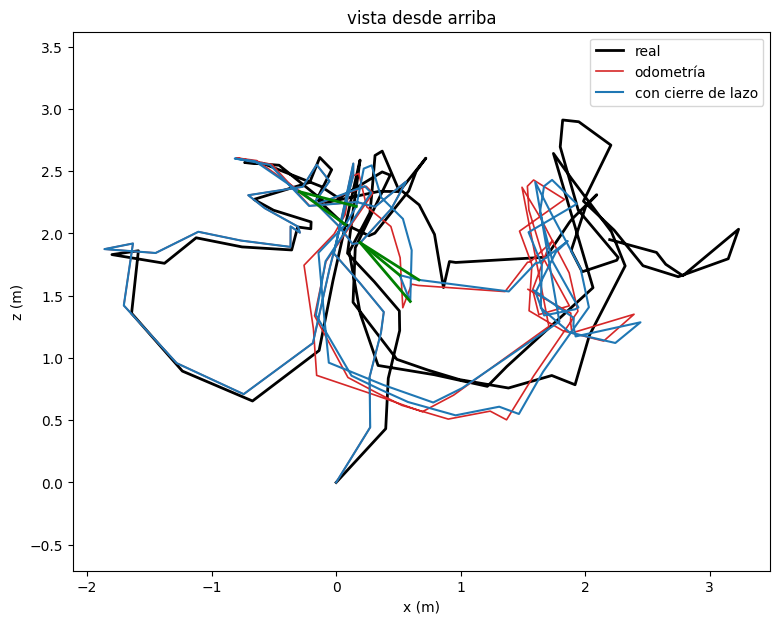

In [ ]:
plt.figure(figsize=(9, 7))
plt.plot(REF[KF, 0, 3], REF[KF, 2, 3], "k", lw=2, label="real")
plt.plot(VO[KF, 0, 3], VO[KF, 2, 3], "tab:red", lw=1.2, label="odometría")
plt.plot(OPT[:, 0, 3], OPT[:, 2, 3], "tab:blue", lw=1.5, label="con cierre de lazo")
for a, b, _ in aristas_lazo:
    plt.plot(OPT[[a, b], 0, 3], OPT[[a, b], 2, 3], "g-", lw=2)
plt.axis("equal"); plt.legend(); plt.xlabel("x (m)"); plt.ylabel("z (m)")
plt.title("vista desde arriba")
plt.show()

el cierre de lazo corrige **hacia atrás**: los keyframes entre los dos extremos del lazo también se mueven, porque la diferencia se reparte por todo el grafo. Pero un lazo solo corrige lo que encierra: si la cámara nunca vuelve a pasar por un lugar, ese tramo conserva su deriva. Por eso los SLAM de verdad buscan lazos todo el tiempo

**y si el lazo es falso?** Le agregamos al grafo un único lazo equivocado: dos keyframes que **no** son el mismo lugar, como si el reconocimiento se hubiera confundido entre dos sillones parecidos

In [ ]:
a, b = 5, len(KF) - 5
falso = (a, b, np.eye(4))  # le mentimos al grafo: "estos dos están en el mismo lugar"
print(f"distancia real entre los keyframes {a} y {b}: "
      f"{np.linalg.norm(REF[KF[a], :3, 3] - REF[KF[b], :3, 3]):.2f} m")

MAL = grafo_de_poses(list(VO[KF]), aristas_odo + aristas_lazo + [falso])
print(f"ATE con los lazos buenos: {ate(OPT, REF[KF]) * 100:.1f} cm")
print(f"ATE con un lazo falso más: {ate(MAL, REF[KF]) * 100:.1f} cm")

distancia real entre los keyframes 5 y 95: 2.96 m
ATE con los lazos buenos: 48.1 cm
ATE con un lazo falso más: 162.5 cm


un solo lazo falso deforma todo el mapa. Por eso los SLAM reales verifican cada lazo con geometría (como nuestro PnP con al menos 60 inliers) y usan pérdidas robustas que pueden "apagar" una arista que no encaja con las demás

##**5.- El mapa**

pegamos las nubes de los keyframes usando sus poses. Usamos un voxel grid de 3 cm para no repetir puntos

In [ ]:
def mapa(poses, voxel=0.03, paso=4):
    puntos, colores = [], []
    for k, T in zip(KF, poses):
        rgb, z = leer(FRAMES[k])
        # tomo un píxel de cada 4 para que no sea tan pesado
        v, u = np.mgrid[0:480:paso, 0:640:paso]
        zz = z[v, u]
        ok = (zz > 0.3) & (zz < 4)
        X = a_3d(u[ok], v[ok], zz[ok])          # puntos en la cámara
        X = X @ T[:3, :3].T + T[:3, 3]          # los paso al mundo con la pose
        puntos.append(X)
        colores.append(rgb[v[ok], u[ok]])
    puntos = np.concatenate(puntos)
    colores = np.concatenate(colores)
    # me quedo con un solo punto por cubo pequeño de 3 cm
    celdas = np.floor(puntos / voxel).astype(int)
    _, idx = np.unique(celdas, axis=0, return_index=True)
    return puntos[idx], colores[idx]

def dibujar(P, col, titulo, n=60000):
    # dibujo una muestra al azar de n puntos (si no, el navegador sufre)
    i = np.random.default_rng(0).choice(len(P), min(n, len(P)), replace=False)
    colores = [f"rgb({r},{g},{b})" for r, g, b in col[i]]
    # dibujo (x, z, -y) para que "arriba" quede arriba
    fig = go.Figure(go.Scatter3d(x=P[i, 0], y=P[i, 2], z=-P[i, 1], mode="markers",
                                 marker=dict(size=1.2, color=colores)))
    fig.update_layout(title=titulo, height=550, scene=dict(aspectmode="data"))
    fig.show()

MAPAS = {"odometría": mapa(VO[KF]),
         "con cierre de lazo": mapa(OPT),
         "con poses reales": mapa(REF[KF])}

dibujar(*MAPAS["odometría"], "mapa con la odometría (se puede rotar con el mouse)")
dibujar(*MAPAS["con poses reales"], "mapa con las poses reales")